# Question 1: Research Abstract Clustering

This notebook prepares research abstracts for text analysis, engineers TF-IDF features, and evaluates a K-Means clustering baseline. Run the notebook from top to bottom so that each stage uses the output of the preceding stage.

## 1. Data loading and initial inspection

Load abstracts and their `ai`/`classical` labels. Question 1 uses only the abstract text for clustering; Question 2 uses the labels to measure predictive performance.

In [55]:
from pathlib import Path
import json
import pandas as pd

parent_dir = Path.cwd().parents[1]
file_path = parent_dir / "Dataset" / "research_abstracts.json"

with open(file_path, "r", encoding="utf-8") as f:
    data = json.load(f)

data = pd.DataFrame(data)[["Abstract", "Label"]]

In [56]:
df = data.copy()
display(df.head())

,Abstract,Label
0,Forward-looking forecasting of the inflation r...,ai
1,Our study examined the disaggregation of infla...,ai
2,This paper develops a dynamic factor model tha...,classical
3,"In this paper, I use a simple SIR Macro model ...",classical
4,BackgroundGame theory is useful for identifyin...,classical


## 2. Text preprocessing

The following steps remove duplicate and missing abstracts, standardise the text, lemmatise words, and remove English stop words. The resulting `stop_removed` column is the final text representation used for exploration and modelling.

### 2.1 Data quality checks

Duplicate records and missing abstracts are removed before text transformation. The printed counts should be zero after each operation.

In [57]:
df = df.drop_duplicates()
print("Duplicate abstracts remaining:", df["Abstract"].duplicated().sum())

Duplicate abstracts remaining: 0


In [58]:
df = df.dropna()
print("Missing abstracts remaining:", df["Abstract"].isna().sum())

Missing abstracts remaining: 0


### 2.2 Text normalisation

Punctuation and repeated whitespace are removed, then the cleaned text is converted to lowercase. This makes equivalent terms consistent before tokenisation.

In [59]:
import re

pattern_one = r'[^\w\s]'
pattern_two = r'\s+'

df['clean_Abstract'] = (
    df['Abstract']
    .str.replace(pattern_one, ' ', regex=True)
    .str.replace(pattern_two, ' ', regex=True)
    .str.strip()
)

In [60]:
df['clean_Abstract'] = df['clean_Abstract'].apply(str.lower)

### 2.3 Lemmatization

Words are reduced to their base forms using part-of-speech-aware WordNet lemmatization. The required NLTK resources are downloaded when this cell is first run.

In [61]:
from nltk import pos_tag, word_tokenize
from nltk.corpus import wordnet
from nltk.stem import WordNetLemmatizer
import nltk

for resource, location in [
    ("punkt_tab", "tokenizers/punkt_tab"),
    ("averaged_perceptron_tagger_eng", "taggers/averaged_perceptron_tagger_eng"),
    ("wordnet", "corpora/wordnet.zip"),
]:
    try:
        nltk.data.find(location)
    except LookupError:
        nltk.download(resource, raise_on_error=True)

lemmatizer = WordNetLemmatizer()

def lemmatize_text(text):
    words = word_tokenize(text)
    tagged_words = pos_tag(words)

    lemmas = []

    for word, tag in tagged_words:
        if tag.startswith('J'):
            pos = wordnet.ADJ
        elif tag.startswith('V'):
            pos = wordnet.VERB
        elif tag.startswith('N'):
            pos = wordnet.NOUN
        elif tag.startswith('R'):
            pos = wordnet.ADV
        else:
            pos = wordnet.NOUN

        lemmas.append(lemmatizer.lemmatize(word, pos))

    return ' '.join(lemmas)

In [62]:
df['text_lemmatized'] = df['clean_Abstract'].apply(lemmatize_text)

### 2.4 Stop-word removal

Common English stop words are removed from the lemmatised abstracts, leaving the terms that are most useful for feature engineering and clustering.

In [63]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

df['stop_removed'] = df['text_lemmatized'].apply(
    lambda x: ' '.join([w for w in x.split() if w.lower() not in ENGLISH_STOP_WORDS])
)

## 3. Exploratory text summary

The word cloud and frequency table provide a quick interpretation of the vocabulary that remains after preprocessing. The final cell compares corpus size before and after stop-word removal.

In [64]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

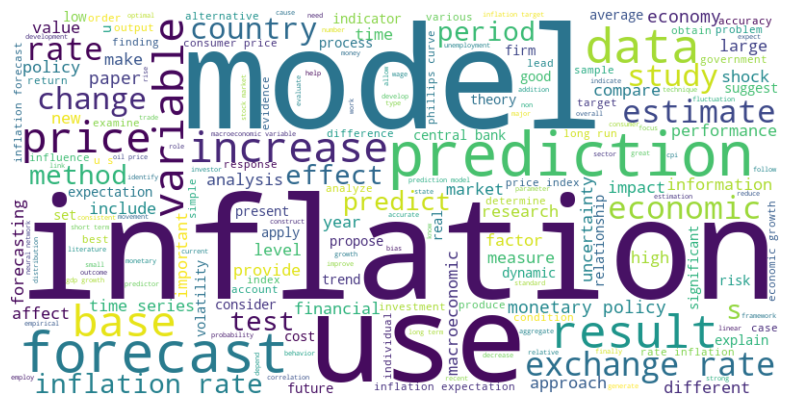

In [65]:
text_data = df["stop_removed"]

combined_string = " ".join(text_data)

wordcloud = WordCloud(
    width=800, 
    height=400, 
    background_color="white", 
    colormap="viridis"
).generate(combined_string)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.show()

In [66]:
from collections import Counter

word_counts = Counter(
    " ".join(df["stop_removed"]).split()
)

word_freq = pd.DataFrame(
    word_counts.items(),
    columns=["word", "frequency"]
).sort_values(
    "frequency",
    ascending=False
)

display(word_freq.head(20))

,word,frequency
3,inflation,2816
38,model,2308
4,rate,1541
53,prediction,1403
14,price,1314
10,use,1213
31,forecast,1155
49,data,842
89,result,688
12,policy,680


In [67]:
print("Number of abstracts:", len(df))
print("Total words before preprocessing:",
      df["clean_Abstract"].str.split().str.len().sum())
print("Total words after preprocessing:",
      df["stop_removed"].str.split().str.len().sum())

Number of abstracts: 1125
Total words before preprocessing: 197871
Total words after preprocessing: 115867


## 4. Feature engineering with TF-IDF

`stop_removed` is used because it is the final preprocessed representation of each abstract. TF-IDF converts the text into numerical features using unigrams and bigrams; the 500-feature cap controls matrix dimensionality while retaining informative terms.

In [68]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    max_features=500,
    ngram_range=(1, 2),
    min_df=2,
)

tfidf_features = tfidf_vectorizer.fit_transform(df["stop_removed"])

tfidf_df = pd.DataFrame(
    tfidf_features.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out(),
    index=df.index,
)

display(tfidf_df.head())
print("Number of abstracts:", tfidf_features.shape[0])
print("Number of engineered features:", tfidf_features.shape[1])

,10,19,2008,2021,ability,accord,account,accuracy,accurate,achieve,...,view,volatility,wage,way,weight,work,world,year,yield,zero
0,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.075056,0.0,0.0,...,0.0,0.00000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0
1,0.0,0.000000,0.0,0.000000,0.125417,0.0,0.0,0.101936,0.0,0.0,...,0.0,0.00000,0.0,0.000000,0.275885,0.0,0.0,0.0,0.120165,0.0
2,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,...,0.0,0.08743,0.0,0.000000,0.000000,0.0,0.0,0.0,0.092771,0.0
3,0.0,0.252049,0.0,0.602186,0.000000,0.0,0.0,0.000000,0.0,0.0,...,0.0,0.00000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0
4,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.000000,0.0,0.0,...,0.0,0.00000,0.0,0.092903,0.000000,0.0,0.0,0.0,0.000000,0.0


Number of abstracts: 1125
Number of engineered features: 500


## 5. Baseline clustering model

K-Means is evaluated with TF-IDF features. The data is split into training and test sets so that silhouette scores can be compared across candidate cluster counts and checked for generalisation.

### 5.1 Prepare the train/test split

An 80/20 split is created with a fixed random seed for reproducibility.

In [69]:
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_tfidf = tfidf_features

X_train, X_test = train_test_split(
    X_tfidf,
    test_size=0.20,
    random_state=42,
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

Training samples: 900
Testing samples: 225
Number of features: 500


### 5.2 Compare candidate cluster counts

Models with two through eight clusters are fitted on the training data. The table reports training and test silhouette scores, their gap, and training inertia for interpretation.

In [70]:
cluster_results = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10,
    )

    train_labels = kmeans.fit_predict(X_train)
    test_labels = kmeans.predict(X_test)

    train_silhouette = silhouette_score(X_train, train_labels)
    test_silhouette = silhouette_score(X_test, test_labels)

    cluster_results.append({
        "Clusters": k,
        "Train Silhouette": train_silhouette,
        "Test Silhouette": test_silhouette,
        "Generalization Gap": train_silhouette - test_silhouette,
        "Training Inertia": kmeans.inertia_,
    })

results_df = pd.DataFrame(cluster_results)
display(results_df)

,Clusters,Train Silhouette,Test Silhouette,Generalization Gap,Training Inertia
0,2,0.016293,0.018545,-0.002252,801.710414
1,3,0.017790,0.018065,-0.000275,790.112327
2,4,0.017984,0.017552,0.000432,780.325788
3,5,0.019397,0.020362,-0.000965,772.640897
4,6,0.019658,0.018570,0.001088,764.859143
5,7,0.022462,0.015249,0.007213,758.025997
6,8,0.022741,0.014564,0.008177,751.386134


### 5.3 Select and evaluate the baseline

The cluster count with the highest test silhouette score is selected. The final baseline is then fitted and its key metrics are reported.

In [71]:
best_k = results_df.loc[
    results_df["Test Silhouette"].idxmax(),
    "Clusters",
]

print("Selected number of clusters:", best_k)

baseline_model = KMeans(
    n_clusters=int(best_k),
    random_state=42,
    n_init=10,
)

train_clusters = baseline_model.fit_predict(X_train)
test_clusters = baseline_model.predict(X_test)

final_train_silhouette = silhouette_score(X_train, train_clusters)
final_test_silhouette = silhouette_score(X_test, test_clusters)
generalization_gap = final_train_silhouette - final_test_silhouette

print("\n===== BASELINE MODEL PERFORMANCE =====")
print("Number of clusters:", best_k)
print("Training silhouette score:", round(final_train_silhouette, 4))
print("Test silhouette score:", round(final_test_silhouette, 4))
print("Generalization gap:", round(generalization_gap, 4))
print("Training inertia:", round(baseline_model.inertia_, 4))

Selected number of clusters: 5

===== BASELINE MODEL PERFORMANCE =====
Number of clusters: 5
Training silhouette score: 0.0194
Test silhouette score: 0.0204
Generalization gap: -0.001
Training inertia: 772.6409


### 5.4 Visualise model performance

The chart compares training and test silhouette scores for every candidate cluster count. Similar scores indicate more consistent performance between the split datasets.

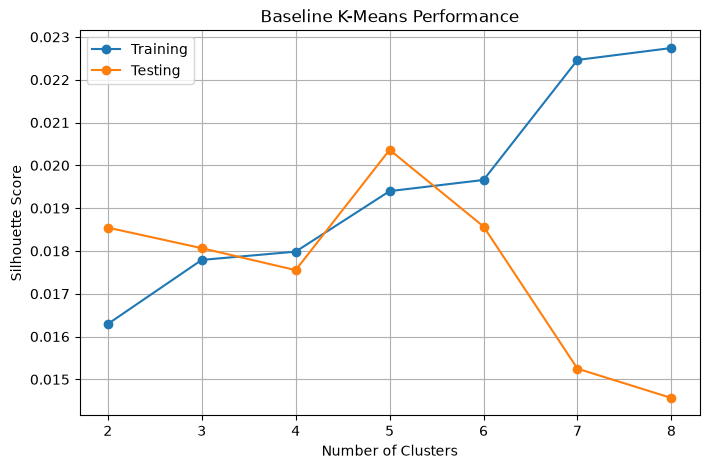

In [72]:
plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Clusters"],
    results_df["Train Silhouette"],
    marker="o",
    label="Training",
)

plt.plot(
    results_df["Clusters"],
    results_df["Test Silhouette"],
    marker="o",
    label="Testing",
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Baseline K-Means Performance")
plt.legend()
plt.grid(True)
plt.show()

# Question 2: Predicting research approach

The dataset includes `ai` and `classical` labels. Question 1 clustered abstracts without using these labels. Here, macro F1 is the primary classification measure because the classes are uneven. Accuracy, balanced accuracy and recall for the smaller `ai` class provide context. Every model uses the same 80/20 split and random seed. TF-IDF for the classifiers is fitted on training text only.

## 2.1 Four models versus the Question 1 baseline

K-Means cluster numbers are arbitrary, so assign each training cluster its majority training label before scoring its test predictions. This converts the fitted Question 1 baseline into a classifier without using test labels in the mapping. Question 1 selected its cluster count using test silhouette and fitted TF-IDF before splitting; consequently this baseline comparison is exploratory, while the four supervised models below use train-only features.

In [73]:
import numpy as np
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, recall_score
from sklearn.feature_extraction.text import TfidfVectorizer

text_train, text_test, y_train, y_test = train_test_split(
    df["stop_removed"], df["Label"], test_size=0.20, random_state=42
)
assert len(text_train) == X_train.shape[0] and len(text_test) == X_test.shape[0]

def model_scores(name, truth, prediction):
    return {
        "Model": name,
        "Accuracy": accuracy_score(truth, prediction),
        "Macro F1": f1_score(truth, prediction, average="macro"),
        "Balanced accuracy": balanced_accuracy_score(truth, prediction),
        "AI recall": recall_score(truth, prediction, pos_label="ai"),
    }

cluster_to_label = {
    cluster: y_train.iloc[np.flatnonzero(train_clusters == cluster)].mode().iloc[0]
    for cluster in np.unique(train_clusters)
}
baseline_predictions = [cluster_to_label[cluster] for cluster in test_clusters]
comparison = [model_scores("K-Means baseline", y_test, baseline_predictions)]

# Refit the same Question 1 feature recipe on training text only.
supervised_vectorizer = TfidfVectorizer(
    max_features=500, ngram_range=(1, 2), min_df=2
)
X_train_supervised = supervised_vectorizer.fit_transform(text_train)
X_test_supervised = supervised_vectorizer.transform(text_test)
print("Training label counts:", y_train.value_counts().to_dict())
print("Test label counts:", y_test.value_counts().to_dict())

Training label counts: {'classical': 711, 'ai': 189}
Test label counts: {'classical': 179, 'ai': 46}


In [74]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic regression": LogisticRegression(max_iter=2000, random_state=42),
    "Linear SVM": LinearSVC(random_state=42),
    "Multinomial Naive Bayes": MultinomialNB(),
    "Random forest": RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
}

for name, model in models.items():
    model.fit(X_train_supervised, y_train)
    predictions = model.predict(X_test_supervised)
    comparison.append(model_scores(name, y_test, predictions))

comparison_df = pd.DataFrame(comparison).set_index("Model")
display(comparison_df.round(4))
print("Macro F1 gain over K-Means:")
display((comparison_df["Macro F1"] - comparison_df.loc["K-Means baseline", "Macro F1"]).round(4))

,Accuracy,Macro F1,Balanced accuracy,AI recall
Model,,,,
K-Means baseline,0.7956,0.4431,0.5000,0.0000
Logistic regression,0.8889,0.7956,0.7525,0.5217
Linear SVM,0.8800,0.8076,0.7954,0.6522
Multinomial Naive Bayes,0.9067,0.8320,0.7879,0.5870
Random forest,0.9111,0.8417,0.7988,0.6087


Macro F1 gain over K-Means:


Model
K-Means baseline           0.0000
Logistic regression        0.3525
Linear SVM                 0.3646
Multinomial Naive Bayes    0.3889
Random forest              0.3986
Name: Macro F1, dtype: float64

The fitted clusters tend to assign the majority class to every abstract, which can make their accuracy look reasonable while their `ai` recall and macro F1 are poor. The supervised models use the known labels during training and are compared on the identical held-out abstracts.

## 2.2 Additional enhancement: cross-validated pipeline tuning

Tune the Naive Bayes pipeline's TF-IDF vocabulary size and smoothing strength with five-fold stratified cross validation **within the training set**. This is one training-only optimisation approach. Then fit the selected pipeline on all training abstracts and evaluate it once on the same test set. Compare it with the default Naive Bayes model from 2.1.

In [75]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

nb_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
    ("classifier", MultinomialNB()),
])
search = GridSearchCV(
    nb_pipeline,
    param_grid={
        "tfidf__max_features": [500, 2000, 5000],
        "classifier__alpha": [0.05, 0.1, 1.0],
    },
    scoring="f1_macro",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    n_jobs=-1,
)
search.fit(text_train, y_train)

tuned_predictions = search.predict(text_test)
tuned_scores = model_scores("Tuned Naive Bayes", y_test, tuned_predictions)
default_scores = comparison_df.loc["Multinomial Naive Bayes"]
enhancement_df = pd.DataFrame([
    default_scores.rename("Default Naive Bayes"),
    pd.Series(tuned_scores).drop("Model").rename("Tuned Naive Bayes"),
])
display(enhancement_df.round(4))
print("Best training-CV parameters:", search.best_params_)
print("Best training-CV macro F1:", round(search.best_score_, 4))
gain = tuned_scores["Macro F1"] - default_scores["Macro F1"]
print("Held-out macro F1 change:", round(gain, 4))
print("Improved on the test set:", gain > 0)

,Accuracy,Macro F1,Balanced accuracy,AI recall
Default Naive Bayes,0.9067,0.8320,0.7879,0.5870
Tuned Naive Bayes,0.9111,0.8536,0.8311,0.6957


Best training-CV parameters: {'classifier__alpha': 0.05, 'tfidf__max_features': 5000}
Best training-CV macro F1: 0.8507
Held-out macro F1 change: 0.0216
Improved on the test set: True


Interpret the final `Improved on the test set` value rather than assuming tuning must help. The test set measures performance once; the cross-validation score chooses parameters without exposing test labels. The data has only 1,125 unique abstracts, so the reported differences may vary on another sample.

### Results from the executed notebook

| Model | Test accuracy | Test macro F1 | AI recall |
|---|---:|---:|---:|
| K-Means baseline | 0.7956 | 0.4431 | 0.0000 |
| Logistic regression | 0.8889 | 0.7956 | 0.5217 |
| Linear SVM | 0.8800 | 0.8076 | 0.6522 |
| Multinomial Naive Bayes | 0.9067 | 0.8320 | 0.5870 |
| Random forest | 0.9111 | 0.8417 | 0.6087 |
| Tuned Naive Bayes | 0.9111 | **0.8536** | **0.6957** |

All four supervised models improved test macro F1 over the K-Means baseline. The five-fold training search selected `alpha=0.05` and 5,000 TF-IDF features for Naive Bayes, improving its held-out macro F1 from 0.8320 to 0.8536 (+0.0216) and `ai` recall from 0.5870 to 0.6957. These are results from this fixed split, not a guarantee on new data.